# Итоговый проект: рекомендации банковских продуктов

Цель проекта — построить воспроизводимую рекомендательную систему, которая по ежемесячной истории клиента ранжирует банковские продукты, исключает уже подключённые и возвращает до семи рекомендаций. В ноутбуке собраны результаты полного EDA, генерации признаков, подбора гиперпараметров и итоговой проверки модели.

Данные: Santander Product Recommendation, 13,6 млн клиент-месяцев, 24 продукта. Основная offline-метрика — **MAP@7**. Дополнительно используются Recall@7, NDCG@7 и product coverage. Разбиение строго временное: обучение до марта 2016 года, validation — апрель 2016 года, test — май 2016 года.

## 1. Окружение и воспроизводимость

Ноутбук использует компактные артефакты DVC. Перед запуском достаточно выполнить `dvc pull`. Тяжёлый CSV повторно не читается: EDA и признаки рассчитаны потоковыми шагами из `dvc.yaml`.

In [1]:
from pathlib import Path
import json
import sqlite3

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display

sns.set_theme(style='whitegrid')
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_ROOT / 'dvc_data' / 'data'
EDA_DIR = DATA_DIR / 'eda'
MODEL_DIR = DATA_DIR / 'baseline'
DOCS_IMAGES = PROJECT_ROOT / 'docs' / 'images'

required = [EDA_DIR / 'summary.json', DATA_DIR / 'features' / 'summary.json', MODEL_DIR / 'metrics.json']
missing = [str(path) for path in required if not path.exists()]
assert not missing, f'Не найдены DVC-артефакты: {missing}. Выполните dvc pull.'
print(f'Корень проекта: {PROJECT_ROOT}')

Корень проекта: /Users/sergeyuser/Documents/Yandex Практикум/проекты/final_project


## 2. Первичный анализ данных

Исходный CSV имеет размер около 2,1 ГБ. Шаг EDA читает его блоками по 100 000 строк, поэтому анализ не требует загрузки всей таблицы в оперативную память.

In [2]:
eda = json.loads((EDA_DIR / 'summary.json').read_text(encoding='utf-8'))
overview = pd.DataFrame({
    'Показатель': ['Строки', 'Уникальные клиенты', 'Месячные снимки', 'Продукты', 'Период', 'Новые подключения'],
    'Значение': [
        f"{eda['rows']:,}", f"{eda['unique_customers']:,}", eda['monthly_snapshots'],
        eda['product_columns'], f"{eda['date_min']} — {eda['date_max']}",
        f"{eda['total_observed_product_additions']:,}",
    ],
})
display(overview.style.hide(axis='index'))

Показатель,Значение
Строки,"13,647,309"
Уникальные клиенты,"956,645"
Месячные снимки,17
Продукты,24
Период,2015-01-28 — 2016-05-28
Новые подключения,"561,710"


### 2.1 Пропуски

Для каждого столбца посчитаны число и доля пропусков. Признаки с почти полной пустотой нельзя напрямую использовать без отдельной стратегии обработки.

,column,missing_count,missing_rate
0,conyuemp,"13,645,501",99.99%
1,ult_fec_cli_1t,"13,622,516",99.82%
2,renta,"2,794,375",20.48%
3,segmento,"189,368",1.39%
4,canal_entrada,"186,126",1.36%
5,indrel_1mes,"149,781",1.10%
6,tiprel_1mes,"149,781",1.10%
7,nomprov,"93,591",0.69%
8,cod_prov,"93,591",0.69%
9,sexo,"27,804",0.20%


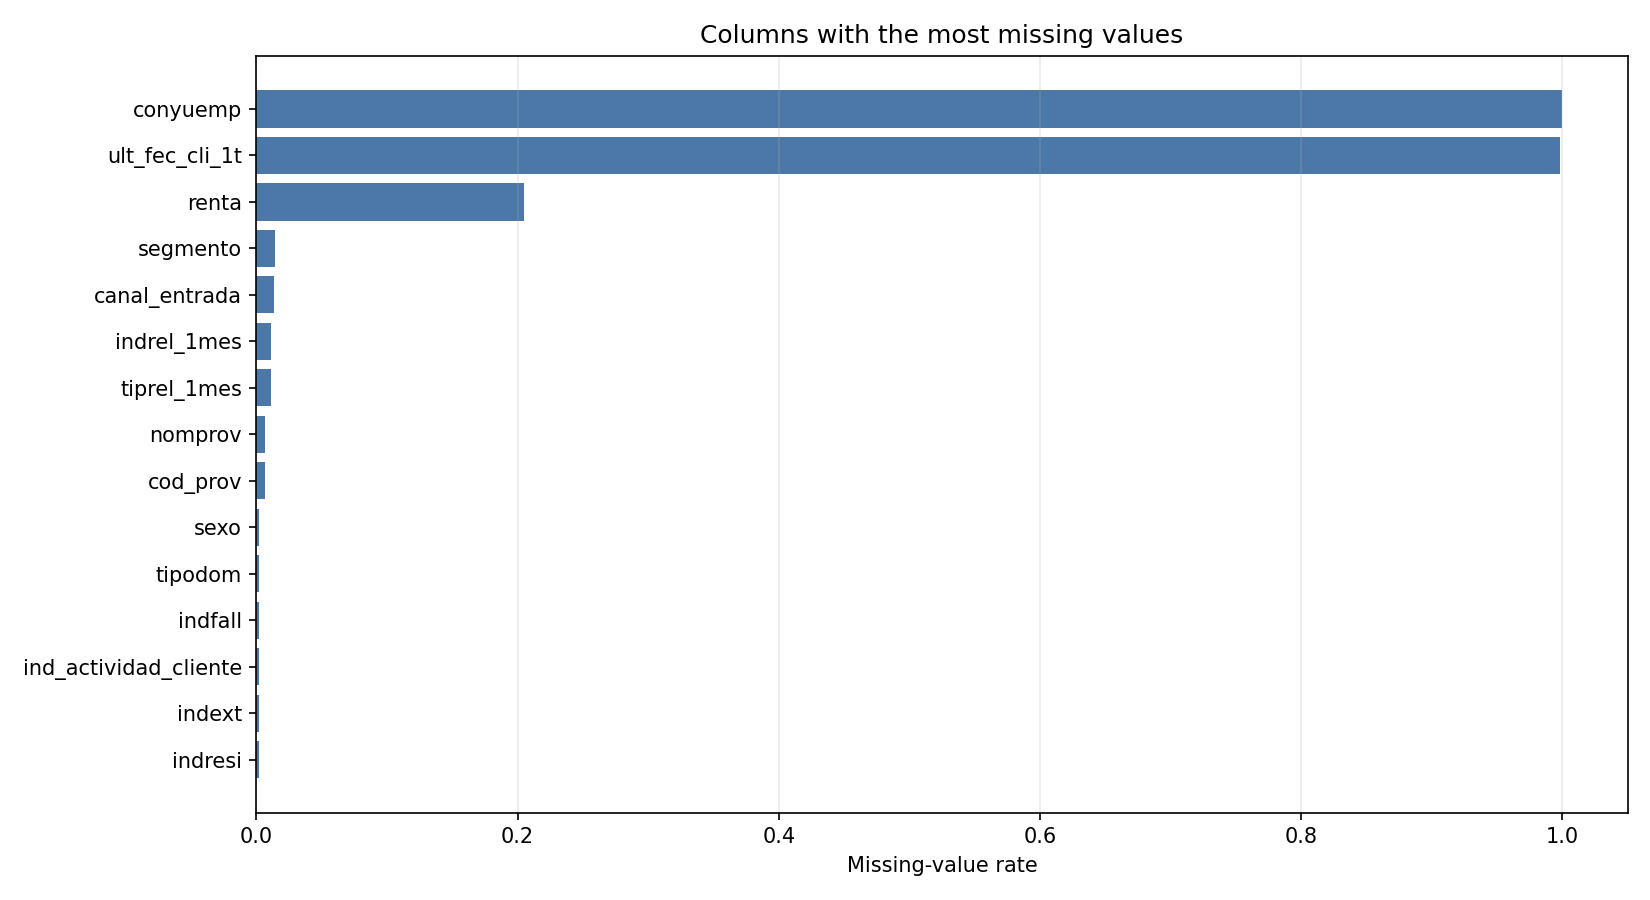

In [3]:
missingness = pd.read_csv(EDA_DIR / 'tables' / 'missingness.csv')
display(missingness.head(12).style.format({'missing_count': '{:,.0f}', 'missing_rate': '{:.2%}'}))
display(Image(filename=str(DOCS_IMAGES / 'missingness.png'), width=950))

**Вывод.** `conyuemp` и `ult_fec_cli_1t` пропущены почти полностью, `renta` — примерно в 20,5% строк. Для baseline используются устойчивые признаки владения продуктами и нормализованный сегмент. Это снижает риск искажений из-за агрессивной импутации сильно разреженных полей.

### 2.2 Дубликаты и временной охват

,fecha_dato,records,duplicate_customer_month_rows,full_duplicate_rows
12,2016-01-28,"916,269",0,0
13,2016-02-28,"920,904",0,0
14,2016-03-28,"925,076",0,0
15,2016-04-28,"928,274",0,0
16,2016-05-28,"931,453",0,0


Повторяющиеся пары клиент-месяц: 0
Полные дубликаты строк: 0


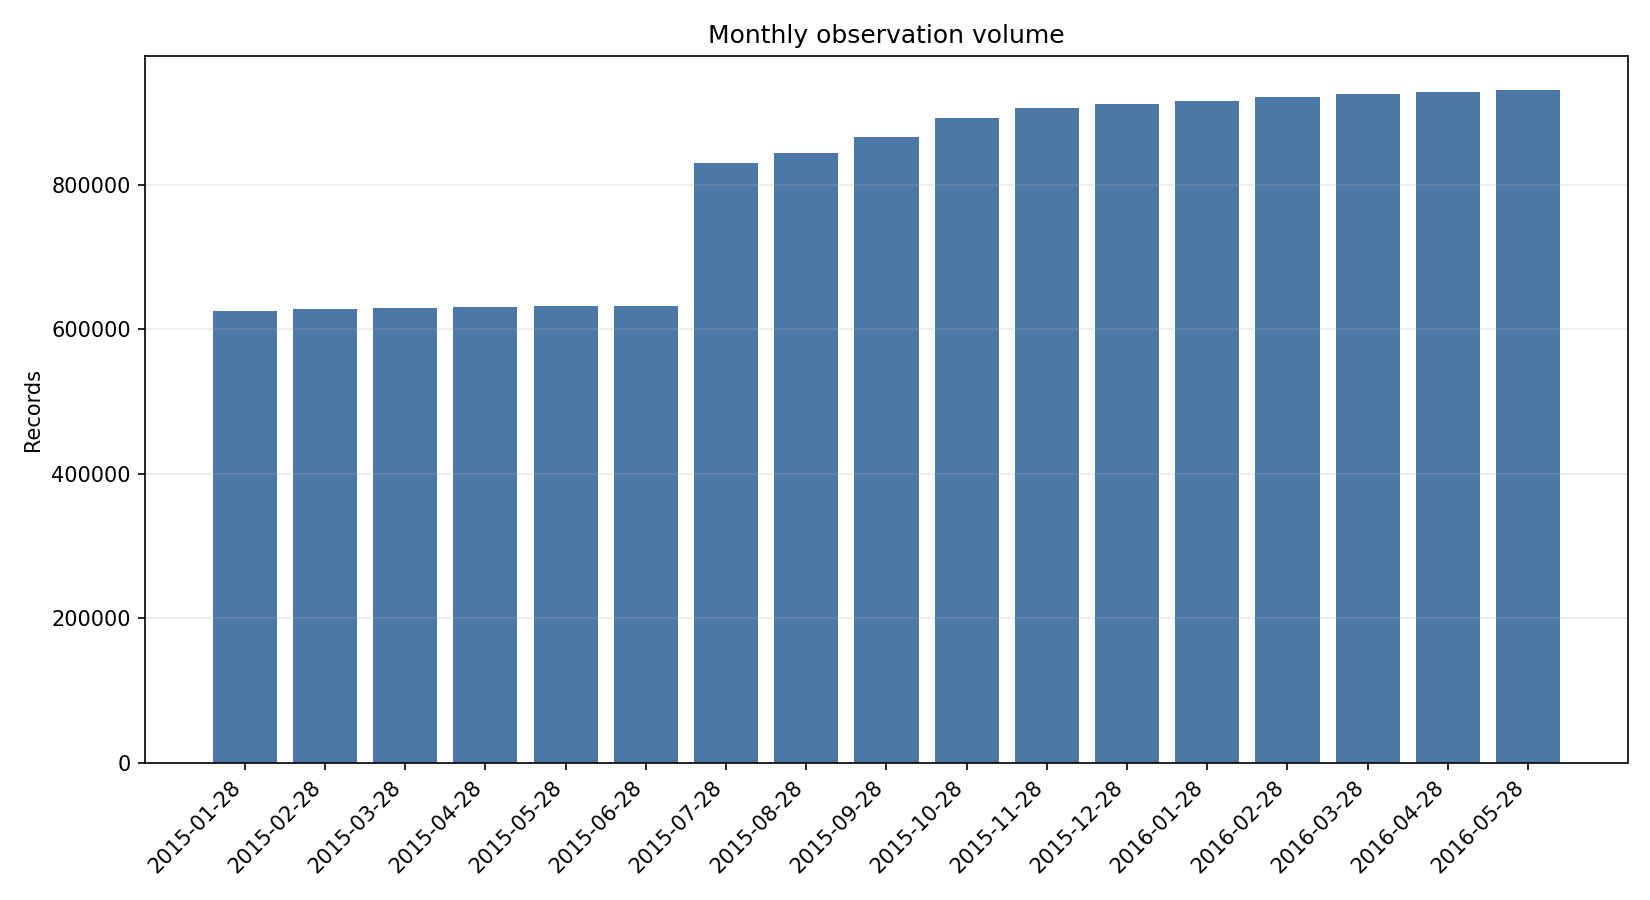

In [4]:
duplicates = pd.read_csv(EDA_DIR / 'tables' / 'duplicate_analysis.csv')
display(duplicates.tail().style.format({'records': '{:,.0f}'}))
print('Повторяющиеся пары клиент-месяц:', int(duplicates['duplicate_customer_month_rows'].sum()))
print('Полные дубликаты строк:', int(duplicates['full_duplicate_rows'].sum()))
display(Image(filename=str(DOCS_IMAGES / 'monthly_observations.png'), width=950))

**Вывод.** Дубликаты ключа «клиент — месяц» и полные дубликаты не обнаружены. Данные отсортированы по времени и подходят для формирования переходов между соседними месяцами. Случайное train/test-разбиение использовать нельзя: оно создало бы утечку будущего.

### 2.3 Выбросы и всплески

Временные всплески выявляются правилом Tukey IQR по месячным темпам изменения числа записей и числа подключений. Это анализ агрегированных временных аномалий, а не автоматическое удаление строк.

,fecha_dato,records,unique_customers,total_additions,records_change_rate,additions_change_rate,records_spike,additions_spike
5,2015-06-28,"632,110",632110,"41,745",0.02%,58.66%,False,True
6,2015-07-28,"829,817",829817,"33,362",31.28%,-20.08%,True,False


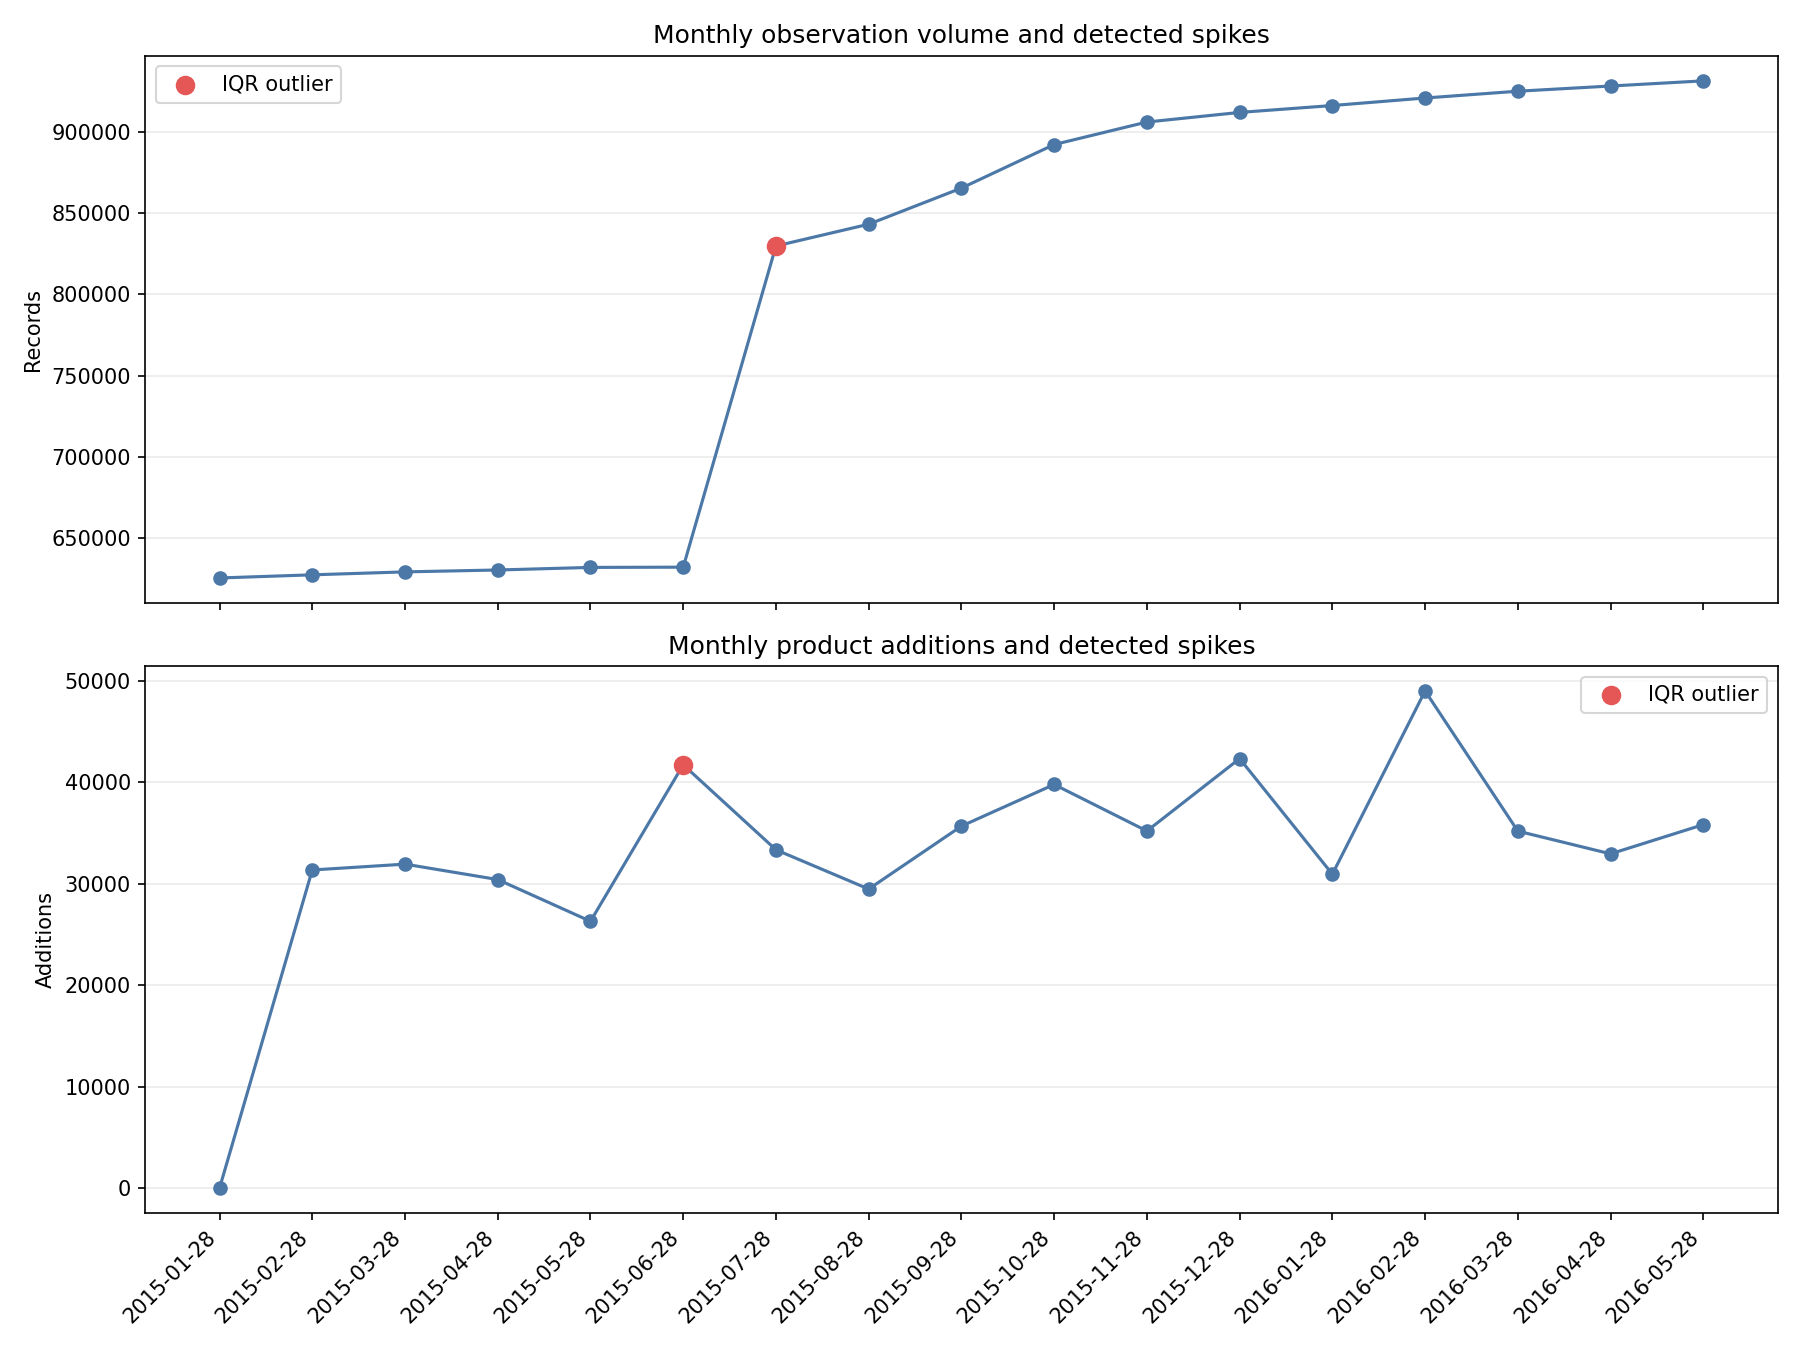

In [5]:
anomalies = pd.read_csv(EDA_DIR / 'tables' / 'monthly_anomalies.csv')
flagged = anomalies.loc[anomalies['records_spike'] | anomalies['additions_spike']]
display(flagged.style.format({'records': '{:,.0f}', 'total_additions': '{:,.0f}', 'records_change_rate': '{:.2%}', 'additions_change_rate': '{:.2%}'}))
display(Image(filename=str(DOCS_IMAGES / 'monthly_spikes.png'), width=950))

**Вывод.** Объём записей резко вырос в июле 2015 года, а подключения — в июне 2015 года. Эти месяцы сохранены: всплески согласованы между агрегатами и могут отражать изменение охвата или бизнес-процессов. Временная валидация проверяет устойчивость модели к таким сдвигам.

### 2.4 Владение продуктами и целевые события

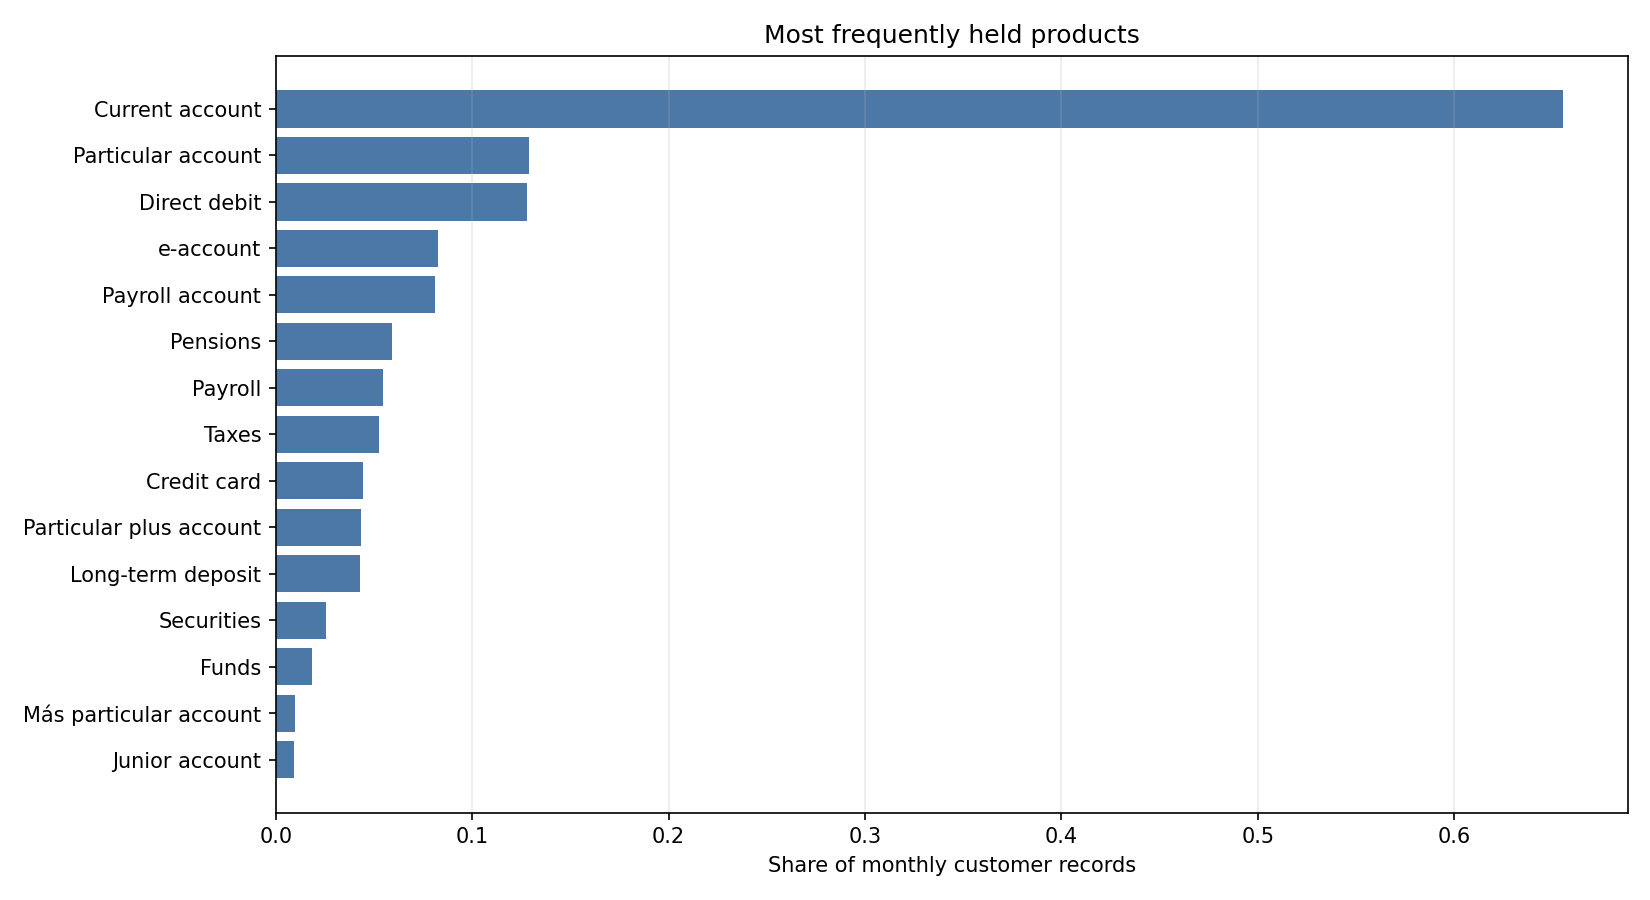

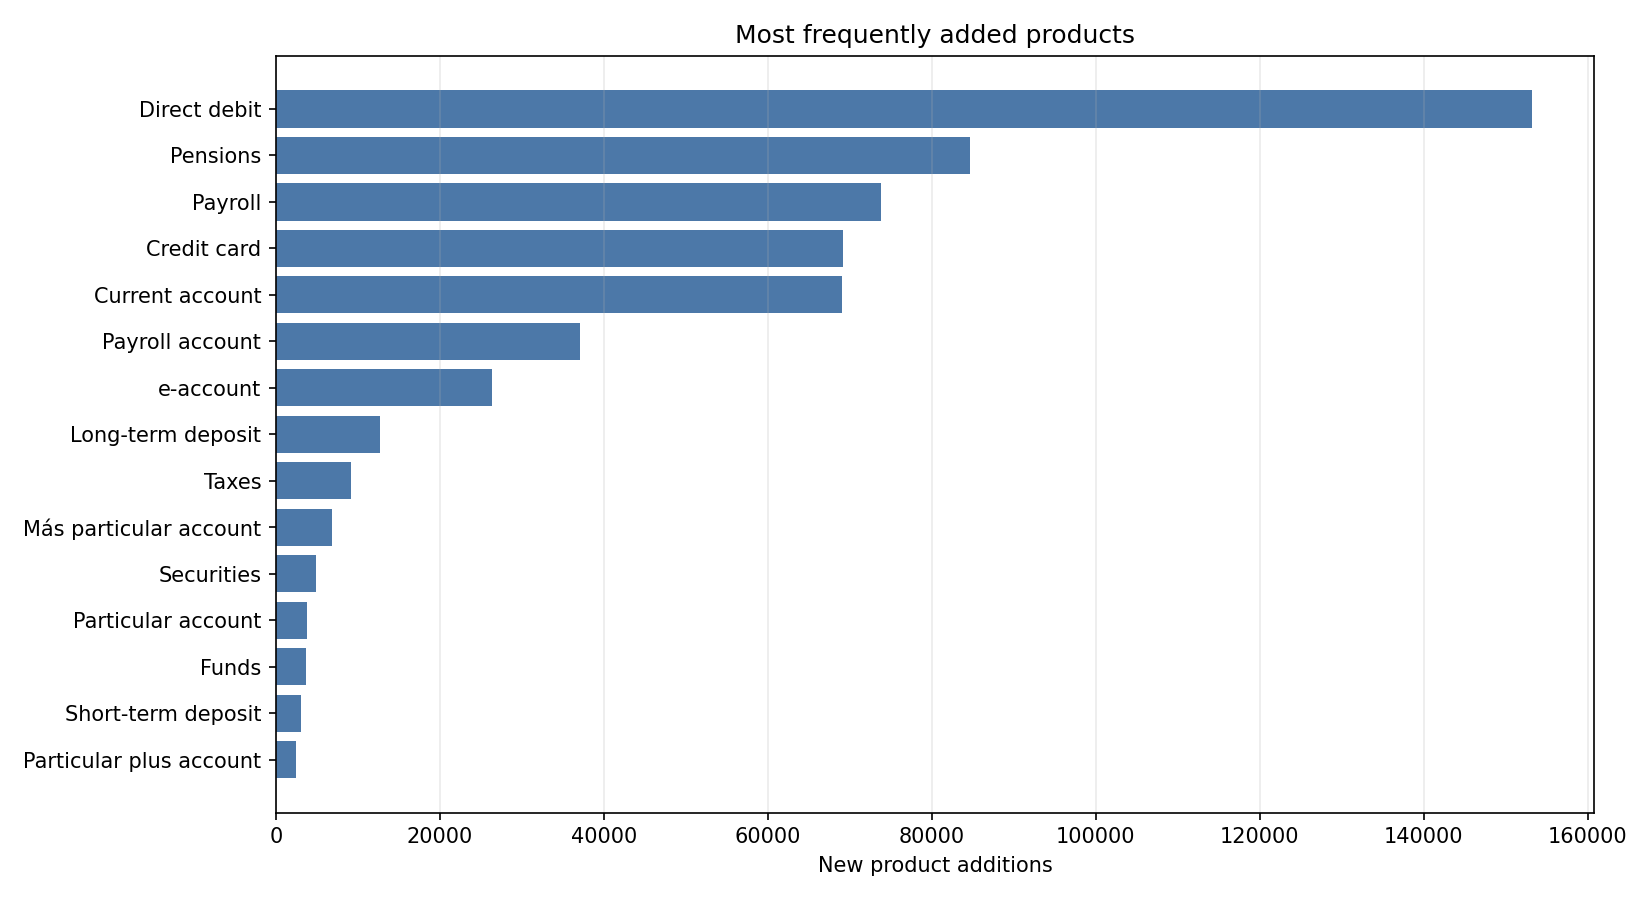

Самый распространённый продукт: ind_cco_fin_ult1 (65.5%)
Чаще всего подключали: ind_recibo_ult1 (153,146 событий)


In [6]:
display(Image(filename=str(DOCS_IMAGES / 'product_prevalence.png'), width=950))
display(Image(filename=str(DOCS_IMAGES / 'product_additions.png'), width=950))
print(f"Самый распространённый продукт: {eda['top_owned_product']} ({eda['top_owned_product_rate']:.1%})")
print(f"Чаще всего подключали: {eda['top_added_product']} ({eda['top_added_product_count']:,} событий)")

**Основные выводы EDA.** Распределение продуктов сильно несбалансировано. Не менее 95,7% клиент-месяцев не содержат нового подключения. Поэтому accuracy неприменима, а основная метрика должна оценивать ранжирование короткого списка. Popularity baseline обязан исключать уже имеющиеся продукты и учитывать клиентский сегмент.

## 3. Генерация признаков

Цель продукта равна 1, если в предыдущем месяце клиент им не владел, а в текущем владеет. В переход включаются только клиенты, присутствующие в обоих соседних снимках. Это не позволяет принять появление нового клиента в базе за одновременное подключение всех его продуктов.

In [7]:
feature_summary = json.loads((DATA_DIR / 'features' / 'summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame({
    'Выборка': ['Validation', 'Test'],
    'Месяц': [feature_summary['validation_month'], feature_summary['test_month']],
    'Клиент-месяцы': [feature_summary['validation_rows'], feature_summary['test_rows']],
    'Положительные метки': [feature_summary['validation_positive_labels'], feature_summary['test_positive_labels']],
}).style.format({'Клиент-месяцы': '{:,.0f}', 'Положительные метки': '{:,.0f}'}))
display(Markdown('**Сформированные признаки:** ' + '; '.join(feature_summary['generated_features']) + '.'))

,Выборка,Месяц,Клиент-месяцы,Положительные метки
0,Validation,2016-04-28,"923,414","32,962"
1,Test,2016-05-28,"926,663","35,843"


**Сформированные признаки:** 24 current-product ownership flags; 24 next-month product-addition targets; normalized customer segment; monthly global product-addition rate; monthly segment product-addition rate; candidate eligibility count.

## 4. Модель и поиск гиперпараметров

Baseline оценивает сглаженную частоту подключения каждого продукта. Итоговый score — смесь глобальной и сегментной популярности. Перебираются окно истории `1/3/6/12`, коэффициент временного затухания `0.8/0.9/1.0` и вес сегмента `0/0.5/1`. Всего 36 конфигураций. Выбор выполняется по MAP@7 на validation; test используется один раз после выбора.

In [8]:
search = pd.read_csv(MODEL_DIR / 'search_results.csv')
metrics = json.loads((MODEL_DIR / 'metrics.json').read_text(encoding='utf-8'))
display(search.head(10).style.format({
    'map_at_k_all': '{:.5f}', 'map_at_k_positive': '{:.5f}',
    'recall_at_k_positive': '{:.5f}', 'ndcg_at_k_positive': '{:.5f}',
    'positive_customer_rate': '{:.2%}', 'product_coverage_at_k': '{:.2%}',
}))
print('Число проверенных конфигураций:', len(search))
print('Лучшие параметры:', metrics['best_params'])

,window,decay,segment_weight,map_at_k_all,map_at_k_positive,recall_at_k_positive,ndcg_at_k_positive,positive_customer_rate,product_coverage_at_k
0,1,0.800000,1.000000,0.01971,0.68073,0.96173,0.75330,2.90%,91.67%
1,1,0.900000,1.000000,0.01971,0.68073,0.96173,0.75330,2.90%,91.67%
2,1,1.000000,1.000000,0.01971,0.68073,0.96173,0.75330,2.90%,91.67%
3,6,0.800000,1.000000,0.01946,0.67204,0.96682,0.74788,2.90%,87.50%
4,12,0.900000,1.000000,0.01942,0.67057,0.96594,0.74815,2.90%,87.50%
5,12,1.000000,1.000000,0.01941,0.67052,0.96553,0.74803,2.90%,87.50%
6,6,0.900000,1.000000,0.01940,0.67021,0.96591,0.74623,2.90%,87.50%
7,6,1.000000,1.000000,0.01938,0.66937,0.96569,0.74552,2.90%,87.50%
8,12,0.800000,1.000000,0.01935,0.66820,0.96608,0.74468,2.90%,87.50%
9,3,0.900000,1.000000,0.01930,0.66658,0.97209,0.74675,2.90%,91.67%


Число проверенных конфигураций: 36
Лучшие параметры: {'window': 1, 'recency_decay': 0.8, 'segment_weight': 1.0, 'recommendation_k': 7, 'rate_smoothing': 1.0}


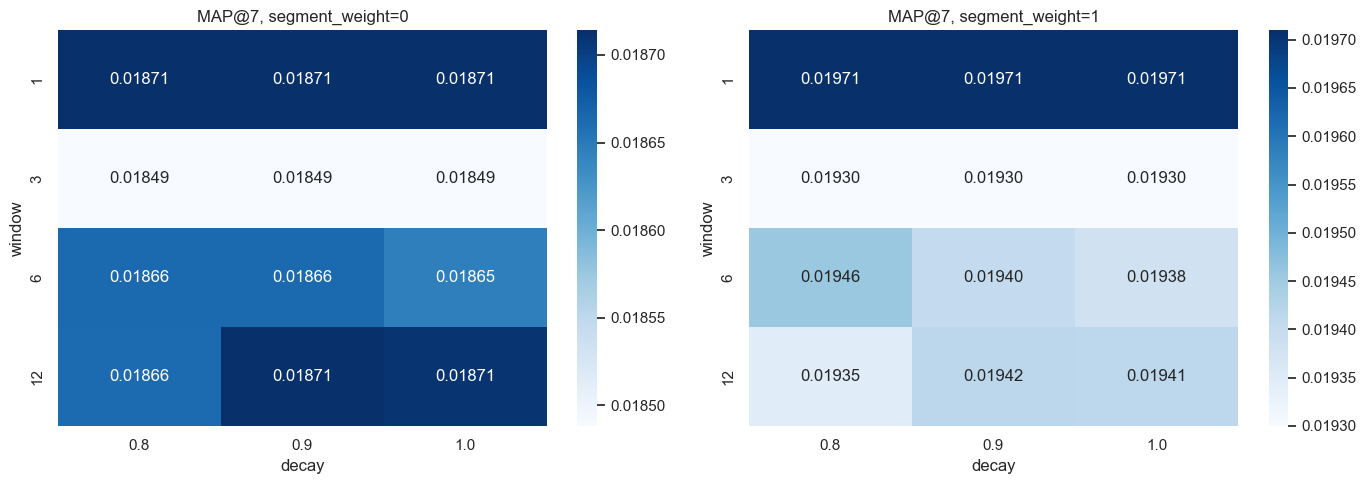

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, weight in zip(axes, [0.0, 1.0]):
    part = search.loc[search['segment_weight'] == weight]
    pivot = part.pivot(index='window', columns='decay', values='map_at_k_all')
    sns.heatmap(pivot, annot=True, fmt='.5f', cmap='Blues', ax=ax)
    ax.set_title(f'MAP@7, segment_weight={weight:g}')
plt.tight_layout()
plt.show()

**Вывод по гиперпараметрам.** Лучшая конфигурация использует один последний месяц и полностью сегментную статистику. При окне 1 коэффициент decay не влияет на расчёт, поэтому значения 0.8, 0.9 и 1.0 дают одинаковый MAP@7; сохранено первое из равных значений. Сегментный признак повысил validation MAP@7 примерно на 5,3% относительно глобального popularity baseline.

## 5. Итоговая оценка

In [10]:
metric_names = {
    'map_at_k_all': 'MAP@7, все клиенты',
    'map_at_k_positive': 'MAP@7, клиенты с подключениями',
    'recall_at_k_positive': 'Recall@7',
    'ndcg_at_k_positive': 'NDCG@7',
    'positive_customer_rate': 'Доля клиентов с подключением',
    'product_coverage_at_k': 'Product coverage',
}
result = pd.DataFrame({
    'Метрика': list(metric_names.values()),
    'Validation': [metrics['validation_metrics'][key] for key in metric_names],
    'Test': [metrics['test_metrics'][key] for key in metric_names],
})
display(result.style.format({'Validation': '{:.5f}', 'Test': '{:.5f}'}))

,Метрика,Validation,Test
0,"MAP@7, все клиенты",0.01971,0.02086
1,"MAP@7, клиенты с подключениями",0.68073,0.69334
2,Recall@7,0.96173,0.97901
3,NDCG@7,0.75330,0.76737
4,Доля клиентов с подключением,0.02895,0.03008
5,Product coverage,0.91667,0.91667


**Интерпретация.** Test MAP@7 равен 0,02086 по всем клиентам и 0,69334 среди клиентов с фактическим подключением. Разница объясняется тем, что только около 3% снимков содержат положительное событие. Recall@7 = 0,979 показывает, что почти все фактически подключённые продукты присутствуют в семи рекомендациях. Coverage = 91,7% означает, что модель использует 22 из 24 продуктов, а не выдаёт один и тот же короткий список всем клиентам.

## 6. Бинарный артефакт и пример inference

In [11]:
binary_model = joblib.load(MODEL_DIR / 'model.pkl')
print('Тип модели:', binary_model['model_type'])
print('Количество продуктов:', len(binary_model['product_columns']))
print('Периоды production-обучения:', binary_model['trained_transition_months'])
print('Параметры:', binary_model['best_params'])

Тип модели: segment_recency_popularity
Количество продуктов: 24
Периоды production-обучения: ['2016-05-28']
Параметры: {'window': 1, 'recency_decay': 0.8, 'segment_weight': 1.0, 'recommendation_k': 7, 'rate_smoothing': 1.0}


In [12]:
import sys
sys.path.insert(0, str(PROJECT_ROOT))
from app.recommender import PopularityRecommender

recommender = PopularityRecommender(MODEL_DIR / 'model.json')
owned = {'ind_cco_fin_ult1', 'ind_recibo_ult1'}
recommendations = recommender.recommend('01', owned, k=7)
pd.DataFrame([{'product': item.product, 'score': item.score} for item in recommendations])

,product,score
0,ind_ecue_fin_ult1,0.043870
1,ind_tjcr_fin_ult1,0.028275
2,ind_nomina_ult1,0.016234
3,ind_nom_pens_ult1,0.015459
4,ind_cno_fin_ult1,0.003467
5,ind_ctop_fin_ult1,0.001457
6,ind_valo_fin_ult1,0.001022


## 7. Логирование в MLflow

Эксперимент `bank_product_recommendations` содержит родительский run `baseline_grid_search` и 36 дочерних запусков. В каждом дочернем run записаны окно, decay, вес сегмента и validation-метрики. Родительский run хранит лучшие параметры, test-метрики и ссылки на модельные артефакты. Локально metadata находятся в SQLite, промышленный Compose использует PostgreSQL; artifact root настроен на S3.

In [13]:
db_path = DATA_DIR / 'mlflow_db' / 'mlflow.db'
with sqlite3.connect(db_path) as connection:
    mlflow_summary = pd.read_sql_query(
        """
        SELECT e.name AS experiment, COUNT(*) AS runs,
               SUM(CASE WHEN r.status = 'FINISHED' THEN 1 ELSE 0 END) AS finished
        FROM runs r JOIN experiments e ON e.experiment_id = r.experiment_id
        GROUP BY e.name ORDER BY e.name
        """, connection
    )
display(mlflow_summary)
print('MLflow UI: ./scripts/start_mlflow.sh → http://127.0.0.1:5001')

,experiment,runs,finished
0,bank_product_recommendations,74,74


MLflow UI: ./scripts/start_mlflow.sh → http://127.0.0.1:5001


## 8. Итог

Получен воспроизводимый baseline рекомендательной системы с временной валидацией, подбором гиперпараметров и промышленным inference-контуром. Модель заметно превосходит общий popularity baseline за счёт сегмента, но остаётся неперсонализированной внутри сегмента. Следующий содержательный эксперимент — модели, учитывающие индивидуальную последовательность владения, давность подключения, возраст и активность клиента. Offline-улучшения следует подтверждать A/B-тестом по конверсии, доходу на контакт и доле нежелательных предложений.